# Duplicatas na base e previsão da base de jogadores

**Introdução à Ciência dos Dados — UFMG — Entrega 3**

**Responsável:** João Tavares

Repositório: https://github.com/pbarruetavena/tp_ciencia_de_dados

Este notebook responde a duas perguntas:

1. **Duplicatas:** a base tem jogos duplicados? A limpeza removeu algum? Eles influenciam os resultados da Entrega 2?
2. **3.4 Previsão de base de jogadores:** é possível prever se um jogo terá alta base de jogadores (`estimated_owners`) usando apenas informações disponíveis na página da Steam antes/durante o lançamento (preço, gênero, desenvolvedor, categorias)? Modelo: **regressão logística**.

**Base:** Steam Games Dataset (Daily Updates), versão fixa 83 (`src/config.py`).

## Configuração

Funciona localmente e no Google Colab. Além das bibliotecas da Entrega 2, usa `scikit-learn`.

In [ ]:
import os, sys
from pathlib import Path

if "google.colab" in sys.modules:
    # Caminho absoluto: rodar a célula de novo não cria clones aninhados
    REPO = "/content/tp_ciencia_de_dados"
    if not os.path.exists(REPO):
        !git clone -q https://github.com/pbarruetavena/tp_ciencia_de_dados.git {REPO}
    else:
        !git -C {REPO} pull -q --ff-only
    %cd {REPO}
    !pip install -q kagglehub
    !python -m src.download_data
    sys.path.insert(0, REPO)
else:
    # Permite importar src/ a partir de notebooks/<pasta>/
    sys.path.insert(0, str(Path.cwd().parents[1]))

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

from src.config import FIGURAS
from src.dados import carregar_jogos
from src.limpeza import com_reviews_minimas, limpar

bruto = carregar_jogos()
jogos = limpar(bruto)
print(f"Base bruta: {bruto.shape}   Base limpa: {jogos.shape}")

Base bruta: (144240, 42)   Base limpa: (144240, 67)


## Parte 1 — Duplicatas

**Pergunta:** existem jogos duplicados na base? Algum foi removido na limpeza? Eles influenciam as análises?

**O que a limpeza faz hoje:** `src.limpeza.limpar()` **não remove nenhuma linha** (a célula acima mostra o mesmo número de linhas antes e depois). O único `drop_duplicates` do módulo serve para listar as faixas de `estimated_owners`, não para remover jogos. Portanto, se houver duplicatas, elas estão em todas as análises da Entrega 2.

### 1.1 Quantas duplicatas existem, por critério

Do critério mais estrito ao mais frouxo:

1. linha inteira idêntica;
2. mesmo `app_id` (identificador da Steam);
3. mesmo nome, desenvolvedor(es) e data de lançamento, com `app_id` diferente;
4. mesmo nome (ignorando maiúsculas e espaços).

In [ ]:
nome = jogos["name"].str.strip().str.lower()
devs = jogos["developers"].map(lambda d: " | ".join(sorted(d)))
chave = pd.DataFrame({"nome": nome, "devs": devs, "data": jogos["release_date"]})

# Só comparamos jogos com nome, desenvolvedor e data preenchidos
completa = chave["nome"].notna() & (chave["devs"] != "") & chave["data"].notna()


def contar(mascara_envolvidas, mascara_extras):
    return {"linhas envolvidas": int(mascara_envolvidas.sum()),
            "linhas a mais": int(mascara_extras.sum())}


niveis = pd.DataFrame({
    "1. linha inteira idêntica": contar(bruto.duplicated(keep=False), bruto.duplicated()),
    "2. mesmo app_id": contar(jogos["app_id"].duplicated(keep=False), jogos["app_id"].duplicated()),
    "3. mesmo nome + dev + data": contar(
        completa & chave.duplicated(keep=False), completa & chave.duplicated()
    ),
    "4. mesmo nome": contar(
        nome.notna() & nome.duplicated(keep=False), nome.notna() & nome.duplicated()
    ),
}).T
niveis["% da base (linhas a mais)"] = (niveis["linhas a mais"] / len(jogos) * 100).round(3)
print(niveis.to_string())

                            linhas envolvidas  linhas a mais  % da base (linhas a mais)
1. linha inteira idêntica                   0              0                      0.000
2. mesmo app_id                             0              0                      0.000
3. mesmo nome + dev + data                172            105                      0.073
4. mesmo nome                            3556           1966                      1.363


**Leitura:**

- Não há linha inteira repetida nem `app_id` repetido: duplicata "exata" não existe na base.
- Existem **nomes repetidos**: 3.556 linhas dividem o nome com outra (1.966 linhas a mais, 1,36% da base).
- Só uma pequena parte delas coincide também em desenvolvedor e data: **172 linhas, 105 a mais (0,07% da base)**.

### 1.2 Homônimos x duplicatas reais

Nome repetido não significa jogo repetido. Separamos os dois casos:

- **Homônimos:** mesmo nome, mas desenvolvedor ou data diferentes (jogos distintos).
- **Duplicatas reais:** mesmo nome, mesmos desenvolvedores e mesma data, com `app_id` diferente (o mesmo jogo cadastrado mais de uma vez na Steam).

In [ ]:
colunas = ["app_id", "name", "release_date", "price", "owners_faixa", "total_reviews"]

print("Nomes mais repetidos:")
print(nome.value_counts().head(8).to_string())

print("\nExemplo de HOMÔNIMOS (nome 'escape': desenvolvedores e datas diferentes):")
print(jogos.loc[nome == "escape", colunas + ["developers"]].to_string(index=False))

Nomes mais repetidos:
name
shadow of the tomb raider: definitive edition    20
escape                                            8
alone                                             7
echo                                              7
cube                                              6
gravity                                           6
in the dark                                       6
hide and seek                                     6

Exemplo de HOMÔNIMOS (nome 'escape': desenvolvedores e datas diferentes):
 app_id   name release_date  price     owners_faixa  total_reviews                   developers
 759010 Escape   2018-01-28    NaN       0 - 20,000             30                [Ragdoll Inc]
1607470 Escape   2021-05-05   3.99       0 - 20,000              8                  [CheYne_CY]
2092070 Escape   2022-08-16   0.00       0 - 20,000             20 [Windshield Wiper Max Games]
2891610 escape   2024-04-17   1.99       0 - 20,000              1                   [GAO PENG]
37

In [ ]:
jogos["dup_grupo"] = np.where(completa, chave.groupby(["nome", "devs", "data"])["nome"].transform("size"), 1)
grupos = jogos[jogos["dup_grupo"] > 1]

print(f"Grupos de duplicatas reais: {chave[completa & (jogos['dup_grupo'] > 1)].drop_duplicates().shape[0]}")
print(f"Linhas envolvidas: {len(grupos)}")
print("\nTamanho dos grupos (nº de linhas do mesmo jogo -> nº de grupos):")
print(grupos.groupby([nome, devs, "release_date"]).size().value_counts().sort_index().to_string())

print("\nExemplo de DUPLICATA REAL (maior grupo):")
maior = grupos[grupos["dup_grupo"] == grupos["dup_grupo"].max()]
print(maior[colunas].sort_values("total_reviews", ascending=False).head(6).to_string(index=False))
print(f"... ({len(maior)} linhas no total)")

print("\nOutros exemplos:")
print(grupos[grupos["dup_grupo"] == 2].sort_values(["name", "app_id"])[colunas].head(8).to_string(index=False))

Grupos de duplicatas reais: 67
Linhas envolvidas: 172

Tamanho dos grupos (nº de linhas do mesmo jogo -> nº de grupos):
2     53
3      8
4      3
5      2
20     1

Exemplo de DUPLICATA REAL (maior grupo):
 app_id                                          name release_date  price          owners_faixa  total_reviews
 750920 Shadow of the Tomb Raider: Definitive Edition   2018-09-14  39.99 2,000,000 - 5,000,000          79443
 905320 Shadow of the Tomb Raider: Definitive Edition   2018-09-14  39.99            0 - 20,000          17872
 849178 Shadow of the Tomb Raider: Definitive Edition   2018-09-14  39.99            0 - 20,000          17861
 849160 Shadow of the Tomb Raider: Definitive Edition   2018-09-14  39.99            0 - 20,000          17665
 890032 Shadow of the Tomb Raider: Definitive Edition   2018-09-14  39.99            0 - 20,000          17664
 890030 Shadow of the Tomb Raider: Definitive Edition   2018-09-14  39.99            0 - 20,000          17566
... (20 linhas n

In [ ]:
# As cópias concordam entre si?
por_grupo = grupos.groupby([nome, devs, "release_date"])
concordancia = pd.Series({
    "mesma faixa de proprietários": (por_grupo["owners_faixa"].nunique(dropna=False) == 1).mean(),
    "mesmo preço": (por_grupo["price"].nunique(dropna=False) == 1).mean(),
    "mesmo total de reviews": (por_grupo["total_reviews"].nunique() == 1).mean(),
}).mul(100).round(1)
print("% dos grupos em que as cópias concordam:")
print(concordancia.to_string())

print("\nFaixa de proprietários: cópia principal (mais reviews) x cópias extras")
principal = grupos.sort_values(["total_reviews", "app_id"], ascending=[False, True]).groupby(
    [nome, devs, "release_date"]
).cumcount() == 0
tabela = pd.DataFrame({
    "principal": grupos.loc[principal, "owners_faixa"].value_counts(sort=False),
    "extras": grupos.loc[~principal, "owners_faixa"].value_counts(sort=False),
})
print(tabela[tabela.sum(axis=1) > 0].to_string())

% dos grupos em que as cópias concordam:
mesma faixa de proprietários    28.4
mesmo preço                     97.0
mesmo total de reviews           7.5

Faixa de proprietários: cópia principal (mais reviews) x cópias extras
                         principal  extras
owners_faixa                              
0 - 20,000                       9      67
20,000 - 50,000                  0       1
50,000 - 100,000                 4       7
100,000 - 200,000                5       4
200,000 - 500,000               10       4
500,000 - 1,000,000              6       3
1,000,000 - 2,000,000           11      10
2,000,000 - 5,000,000           11       3
5,000,000 - 10,000,000           7       1
10,000,000 - 20,000,000          2       1
20,000,000 - 50,000,000          1       0


**Leitura:**

- **Homônimos são a grande maioria dos nomes repetidos.** São nomes genéricos (*Escape*, *Alone*, *Echo*, *Cube*) de desenvolvedores e anos diferentes. São jogos distintos e devem ficar na base.
- **Duplicatas reais: 67 jogos em 172 linhas.** 53 aparecem duas vezes; o caso extremo é *Shadow of the Tomb Raider: Definitive Edition*, com 20 linhas. São quase todos jogos grandes (Call of Duty, Assassin's Creed, Batman), que a Steam cadastra sob mais de um `app_id`.
- **As cópias não trazem os mesmos números.** O preço é igual em 97% dos grupos, mas a faixa de proprietários só coincide em 28% e o total de reviews em 7,5%.
- **As cópias extras carregam um rótulo errado.** Das 66 entradas principais com faixa conhecida, 57 estão acima de 20 mil donos. Das 101 cópias extras, 67 estão na faixa 0–20 mil. Ou seja, um jogo com milhões de donos aparece também como jogo pequeno.

### 1.3 Regra de remoção

Para cada grupo de duplicatas reais mantemos **a linha com mais reviews** (a entrada principal do jogo na Steam; empate: menor `app_id`) e descartamos as outras. Homônimos são mantidos, porque são jogos diferentes.

In [ ]:
def sem_duplicatas(df: pd.DataFrame) -> pd.DataFrame:
    """Remove cópias do mesmo jogo (mesmo nome, desenvolvedores e data), mantendo a de mais reviews."""
    nome = df["name"].str.strip().str.lower()
    devs = df["developers"].map(lambda d: " | ".join(sorted(d)))
    completa = nome.notna() & (devs != "") & df["release_date"].notna()

    ordenado = df.assign(_nome=nome, _devs=devs).sort_values(
        ["total_reviews", "app_id"], ascending=[False, True]
    )
    extra = ordenado[completa.loc[ordenado.index]].duplicated(
        subset=["_nome", "_devs", "release_date"], keep="first"
    )
    return df.drop(index=extra[extra].index)


jogos_dedup = sem_duplicatas(jogos)
removidas = jogos.drop(index=jogos_dedup.index)
print(f"Base completa: {len(jogos):,}   Sem duplicatas reais: {len(jogos_dedup):,}   "
      f"Removidas: {len(removidas):,} ({len(removidas) / len(jogos) * 100:.3f}%)")

Base completa: 144,240   Sem duplicatas reais: 144,135   Removidas: 105 (0.073%)


### 1.4 As duplicatas influenciam os resultados?

Recalculamos as principais estatísticas da Entrega 2 em três versões da base:

- **completa:** como foi usada na Entrega 2;
- **sem duplicatas reais:** aplicando a regra acima;
- **sem nomes repetidos:** cenário extremo, que mantém só uma linha por nome (remove também os homônimos). Serve como limite superior do efeito.

In [ ]:
def metricas(df: pd.DataFrame) -> dict:
    r = {"Jogos": len(df)}

    # 3.1 Preço x avaliações (jogos com 20+ reviews)
    a = com_reviews_minimas(df, n=20).dropna(subset=["price", "taxa_positiva"])
    r["3.1 Spearman preço x taxa positiva"] = stats.spearmanr(a["price"], a["taxa_positiva"])[0]
    r["3.1 Mediana taxa positiva, pagos"] = a.loc[a["price_status"] == "paid", "taxa_positiva"].median()
    r["3.1 Mediana taxa positiva, gratuitos"] = a.loc[a["price_status"] == "free", "taxa_positiva"].median()

    # 3.2 Sazonalidade (2014-2025)
    janela = df[(df["ano"] >= 2014) & (df["ano"] <= 2025)]
    prop = pd.crosstab(janela["ano"], janela["mes"], normalize="index").mean()
    r["3.2 Razão lançamentos out/jan"] = prop[10] / prop[1]
    com_owners = janela.dropna(subset=["owners_mid"])
    for t in (1, 4):
        q = com_owners[com_owners["trimestre"] == t]
        r[f"3.2 % acima de 20k donos, Q{t}"] = (q["owners_mid"] > 20_000).mean() * 100

    # 3.3 Long tail
    x = df["owners_mid"].dropna()
    q1, q2, q3 = x.quantile([0.25, 0.5, 0.75])
    ls = q3 + 1.5 * (q3 - q1)
    r["3.3 Média de proprietários"] = x.mean()
    r["3.3 % dos jogadores nos outliers"] = x[x > ls].sum() / x.sum() * 100
    cauda = x[x > q2]
    q1c, q3c = cauda.quantile([0.25, 0.75])
    ls_cauda = q3c + 1.5 * (q3c - q1c)
    r["3.3 % dos jogos que são mega-hits"] = (x > ls_cauda).mean() * 100
    r["3.3 % dos jogadores nos mega-hits"] = x[x > ls_cauda].sum() / x.sum() * 100

    # 3.5 Preço x tempo jogado
    v = df.dropna(subset=["price", "average_playtime_forever", "median_playtime_forever"])
    r["3.5 Jogos com tempo de jogo"] = len(v)
    r["3.5 Spearman preço x tempo jogado"] = stats.spearmanr(v["price"], v["average_playtime_forever"])[0]
    return r


um_por_nome = jogos.sort_values(["total_reviews", "app_id"], ascending=[False, True])
um_por_nome = um_por_nome[um_por_nome["name"].isna() | ~um_por_nome["name"].str.strip().str.lower().duplicated()]

comparacao = pd.DataFrame({
    "completa": metricas(jogos),
    "sem duplicatas reais": metricas(jogos_dedup),
    "sem nomes repetidos": metricas(um_por_nome),
})
comparacao["variação % (dup. reais)"] = (comparacao["sem duplicatas reais"] / comparacao["completa"] - 1) * 100
comparacao["variação % (nomes)"] = (comparacao["sem nomes repetidos"] / comparacao["completa"] - 1) * 100


def formatar(v):
    return f"{v:,.0f}" if abs(v) >= 1000 else f"{v:.4f}"


exibir = comparacao.copy()
for c in ["completa", "sem duplicatas reais", "sem nomes repetidos"]:
    exibir[c] = comparacao[c].map(formatar)
for c in ["variação % (dup. reais)", "variação % (nomes)"]:
    exibir[c] = comparacao[c].map(lambda v: f"{v:+.2f}%")
print(exibir.to_string())

                                     completa sem duplicatas reais sem nomes repetidos variação % (dup. reais) variação % (nomes)
Jogos                                 144,240              144,135             142,274                  -0.07%             -1.36%
3.1 Spearman preço x taxa positiva     0.0822               0.0828              0.0821                  +0.76%             -0.05%
3.1 Mediana taxa positiva, pagos       0.8182               0.8182              0.8182                  +0.00%             +0.00%
3.1 Mediana taxa positiva, gratuitos   0.7917               0.7917              0.7917                  +0.00%             +0.00%
3.2 Razão lançamentos out/jan          1.5533               1.5541              1.5513                  +0.05%             -0.13%
3.2 % acima de 20k donos, Q1          24.8284              24.8251             24.9194                  -0.01%             +0.37%
3.2 % acima de 20k donos, Q4          22.4762              22.4750             22.5995    

**Resultado:** remover as 105 cópias não muda nenhuma estatística da Entrega 2 de forma relevante.

- A maior variação é na média de proprietários: 87.249 → 86.886 (−0,42%).
- As correlações ficam iguais na prática: 3.1 passa de 0,0822 para 0,0828 e 3.5 de 0,3335 para 0,3333.
- A razão de lançamentos outubro/janeiro (1,55) e a concentração de jogadores nos outliers (90,9%) e nos mega-hits (78,6% → 78,5%) não mudam.
- Mesmo no cenário extremo, tirando as 1.966 linhas de nome repetido, nenhuma estatística varia 1%.

**Conclusão da Parte 1:**

- **Foram removidas duplicatas na limpeza?** Não. `limpar()` não remove linhas.
- **Existem duplicatas?** Sim, mas poucas: 105 linhas a mais (0,07% da base), de 67 jogos cadastrados mais de uma vez. Os outros nomes repetidos são homônimos.
- **Elas influenciam os resultados?** Não. As conclusões da Entrega 2 valem com ou sem elas, porque o volume é pequeno demais diante de 144 mil jogos.
- **Onde elas importam:** em análises jogo a jogo (a cópia extra de um jogo grande aparece como "0–20 mil donos") e em modelos preditivos (a mesma entrada pode cair no treino e no teste). Por isso a Parte 2 usa a base sem duplicatas reais.

## Parte 2 — 3.4 Previsão de base de jogadores

**Pergunta de pesquisa:** É possível prever se um jogo terá alta base de jogadores (`estimated_owners`) usando apenas informações disponíveis na página da Steam antes/durante o lançamento (preço, gênero, desenvolvedor, categorias)?

**Modelo:** regressão logística.

### 2.1 Desenho

**Variável alvo.** `estimated_owners` vem em faixas e ~79% dos jogos estão na primeira (0–20 mil). Definimos:

- **alta base = 1** se o jogo está **acima da primeira faixa** (mais de 20 mil proprietários);
- **alta base = 0** se está na faixa 0–20 mil.

É o mesmo corte usado como "taxa de escape" na pergunta 3.2 e é o único corte que a granularidade da base permite sem deixar a classe positiva minúscula.

**Atributos (só o que existe antes/durante o lançamento):**

| Atributo | Como entra no modelo |
|---|---|
| Preço | `log_price` (padronizado) e indicador de jogo gratuito |
| Gênero | uma coluna 0/1 por gênero (um jogo pode ter vários) |
| Categorias | uma coluna 0/1 por categoria |
| Desenvolvedor | `log(1 + nº de outros jogos do desenvolvedor)`; há ~90 mil desenvolvedores, então uma coluna por desenvolvedor é inviável |

**Fora do modelo, por vazamento de dados** (só existem depois do lançamento): reviews, recomendações, tempo jogado, `peak_ccu`, Metacritic e `tags` (definidas pelos usuários). A categoria **Steam Trading Cards** também fica fora: a Steam só libera cartas depois que o jogo atinge um patamar de vendas, então ela é consequência do sucesso, não informação de lançamento.

**Base de modelagem:** base sem duplicatas reais (Parte 1), só jogos com faixa de proprietários e preço conhecidos.

In [ ]:
ALVO_CORTE = 20_000

base = jogos_dedup.dropna(subset=["owners_mid", "price"]).copy()
base["alta_base"] = (base["owners_mid"] > ALVO_CORTE).astype(int)
base["gratuito_num"] = (base["price"] == 0).astype(int)

print(f"Jogos na base de modelagem: {len(base):,}")
print(f"Alta base (> {ALVO_CORTE:,} donos): {base['alta_base'].sum():,} ({base['alta_base'].mean() * 100:.1f}%)")
print(f"Baixa base: {(1 - base['alta_base']).sum():,} ({(1 - base['alta_base'].mean()) * 100:.1f}%)")

Jogos na base de modelagem: 121,659
Alta base (> 20,000 donos): 25,115 (20.6%)
Baixa base: 96,544 (79.4%)


### 2.2 Análise exploratória

Antes do modelo, olhamos a taxa de alta base por atributo. A linha tracejada é a taxa geral.

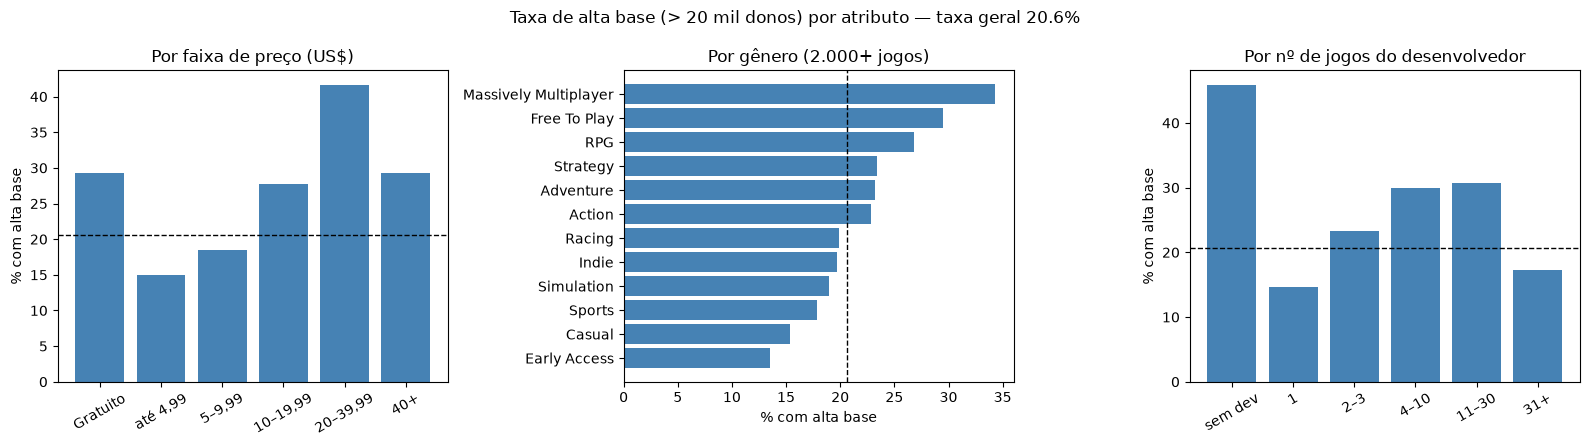

          % alta base  jogos
price                       
Gratuito         29.3  12060
até 4,99         15.0  53513
5–9,99           18.5  29421
10–19,99         27.7  19936
20–39,99         41.6   5184
40+              29.3   1545

            % alta base  jogos
developers                    
sem dev            45.8     96
1                  14.7  56566
2–3                23.4  28838
4–10               30.0  19632
11–30              30.7   9423
31+                17.3   7104

                       % alta base  jogos
genres                                   
Massively Multiplayer         34.3   2246
Free To Play                  29.5   8451
RPG                           26.8  22150
Strategy                      23.4  24777
Adventure                     23.2  46975
Action                        22.9  48296
Racing                        19.9   4140
Indie                         19.7  86958
Simulation                    19.0  26826
Sports                        17.8   4982
Casual        

In [ ]:
taxa_geral = base["alta_base"].mean() * 100

faixa_preco = pd.cut(
    base["price"], bins=[-0.01, 0, 4.99, 9.99, 19.99, 39.99, np.inf],
    labels=["Gratuito", "até 4,99", "5–9,99", "10–19,99", "20–39,99", "40+"],
)
por_preco = base.groupby(faixa_preco, observed=True)["alta_base"].agg(["mean", "size"])

generos = base[["alta_base", "genres"]].explode("genres")
por_genero = generos.groupby("genres")["alta_base"].agg(["mean", "size"])
por_genero = por_genero[por_genero["size"] >= 2000].sort_values("mean")

n_dev = base["developers"].explode().value_counts()
jogos_dev = base["developers"].map(lambda d: max((n_dev[x] for x in d), default=0))
faixa_dev = pd.cut(jogos_dev, bins=[-1, 0, 1, 3, 10, 30, np.inf],
                   labels=["sem dev", "1", "2–3", "4–10", "11–30", "31+"])
por_dev = base.groupby(faixa_dev, observed=True)["alta_base"].agg(["mean", "size"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, tab, titulo, horizontal in [
    (axes[0], por_preco, "Por faixa de preço (US$)", False),
    (axes[1], por_genero, "Por gênero (2.000+ jogos)", True),
    (axes[2], por_dev, "Por nº de jogos do desenvolvedor", False),
]:
    valores = tab["mean"] * 100
    if horizontal:
        ax.barh(valores.index.astype(str), valores.values, color="steelblue")
        ax.axvline(taxa_geral, color="black", linestyle="--", linewidth=1)
        ax.set_xlabel("% com alta base")
    else:
        ax.bar(valores.index.astype(str), valores.values, color="steelblue")
        ax.axhline(taxa_geral, color="black", linestyle="--", linewidth=1)
        ax.set_ylabel("% com alta base")
        ax.tick_params(axis="x", labelrotation=30)
    ax.set_title(titulo)
fig.suptitle(f"Taxa de alta base (> 20 mil donos) por atributo — taxa geral {taxa_geral:.1f}%")
plt.tight_layout()
fig.savefig(FIGURAS / "previsao_owners_eda.png", dpi=150, bbox_inches="tight")
plt.show()

print(por_preco.assign(mean=lambda t: (t["mean"] * 100).round(1)).rename(columns={"mean": "% alta base", "size": "jogos"}).to_string())
print()
print(por_dev.assign(mean=lambda t: (t["mean"] * 100).round(1)).rename(columns={"mean": "% alta base", "size": "jogos"}).to_string())
print()
print(por_genero.sort_values("mean", ascending=False).assign(mean=lambda t: (t["mean"] * 100).round(1)).rename(columns={"mean": "% alta base", "size": "jogos"}).to_string())

**O que os gráficos mostram:**

- **Preço:** a relação não é monotônica. Jogos gratuitos têm taxa alta (29,3%), os mais baratos têm a menor (15,0% até US\$ 4,99) e a taxa sobe com o preço até 41,6% na faixa de US\$ 20–39,99. Por isso o modelo recebe o preço em log e um indicador separado de jogo gratuito.
- **Gênero:** Massively Multiplayer (34,3%), Free To Play (29,5%) e RPG (26,8%) ficam acima da taxa geral; Casual (15,3%) e Early Access (13,5%) ficam abaixo.
- **Desenvolvedor:** quem tem um único jogo na base tem a menor taxa (14,7%); com 4 a 30 jogos ela chega a ~30%. Acima de 30 jogos volta a cair (17,3%): são estúdios que publicam muitos jogos pequenos. A barra "sem dev" tem só 96 jogos e não deve ser lida.

Cada atributo carrega algum sinal, mas nenhum separa bem as duas classes sozinho.

### 2.3 Modelo

- **Divisão:** 80% treino / 20% teste, estratificada pelo alvo (`random_state=42`). O teste só é usado na avaliação final.
- **Pré-processamento dentro do pipeline**, ajustado só no treino (evita vazamento do teste):
  - preço: `log_price` padronizado + indicador de gratuito;
  - gêneros e categorias: colunas 0/1, mantendo só valores que aparecem em pelo menos 200 jogos do treino (descarta rótulos raros e em outros idiomas);
  - desenvolvedor: nº de **outros** jogos do desenvolvedor no treino (o próprio jogo não conta), em `log1p`.
- **Classes desbalanceadas (~21% positivas):** `class_weight="balanced"`, que dá mais peso à classe rara. As métricas principais são AUC-ROC, AUC-PR e F1, não a acurácia.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

SEMENTE = 42
CATEGORIAS_VAZAMENTO = {"Steam Trading Cards"}
MIN_JOGOS = 200  # frequência mínima de um gênero/categoria no treino


def lista_completa(lista):
    return list(lista)


def categorias_sem_vazamento(lista):
    return [c for c in lista if c not in CATEGORIAS_VAZAMENTO]


class FrequenciaDev(BaseEstimator, TransformerMixin):
    """log1p do nº de outros jogos do desenvolvedor no treino (o maior, se houver vários)."""

    def fit(self, X, y=None):
        self.contagem_ = X.iloc[:, 0].explode().value_counts().to_dict()
        return self

    def _frequencia(self, X, desconto):
        n = [max((self.contagem_.get(d, 0) - desconto for d in devs), default=0) for devs in X.iloc[:, 0]]
        return np.log1p(np.clip(n, 0, None)).reshape(-1, 1)

    def transform(self, X):
        return self._frequencia(X, desconto=0)

    def fit_transform(self, X, y=None):
        # No treino o próprio jogo está na contagem: descontamos 1
        return self.fit(X)._frequencia(X, desconto=1)

    def get_feature_names_out(self, input_features=None):
        return np.array(["log_jogos_do_dev"])


def montar_modelo(grupos, categorias=categorias_sem_vazamento):
    """Pipeline de pré-processamento + regressão logística só com os grupos de atributos pedidos."""
    disponiveis = {
        "preço": [
            ("preco_log", StandardScaler(), ["log_price"]),
            ("preco_gratuito", "passthrough", ["gratuito_num"]),
        ],
        "gênero": [("genero", CountVectorizer(analyzer=lista_completa, binary=True, min_df=MIN_JOGOS), "genres")],
        "categorias": [("categoria", CountVectorizer(analyzer=categorias, binary=True, min_df=MIN_JOGOS), "categories")],
        "desenvolvedor": [("dev", make_pipeline(FrequenciaDev(), StandardScaler()), ["developers"])],
        "ano": [("ano", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["ano_num"])],
    }
    transformadores = [t for g in grupos for t in disponiveis[g]]
    return Pipeline([
        ("pre", ColumnTransformer(transformadores)),
        ("logistica", LogisticRegression(class_weight="balanced", max_iter=2000)),
    ])


base["ano_num"] = base["ano"].astype("float")
colunas_x = ["log_price", "gratuito_num", "genres", "categories", "developers", "ano_num"]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    base[colunas_x], base["alta_base"], test_size=0.2, stratify=base["alta_base"], random_state=SEMENTE
)
print(f"Treino: {len(X_treino):,} jogos ({y_treino.mean() * 100:.1f}% alta base)")
print(f"Teste:  {len(X_teste):,} jogos ({y_teste.mean() * 100:.1f}% alta base)")

ATRIBUTOS = ["preço", "gênero", "categorias", "desenvolvedor"]
modelo = montar_modelo(ATRIBUTOS).fit(X_treino, y_treino)
print(f"\nColunas do modelo: {modelo['logistica'].coef_.shape[1]}")

Treino: 97,327 jogos (20.6% alta base)
Teste:  24,332 jogos (20.6% alta base)



Colunas do modelo: 75


### 2.4 Avaliação

- **H₀:** o modelo não distingue jogos de alta e baixa base melhor que o acaso (AUC-ROC = 0,5).
- **H₁:** o modelo distingue melhor que o acaso (AUC-ROC > 0,5).
- **Teste:** IC 95% da AUC-ROC no conjunto de teste por **bootstrap** (2.000 reamostragens, percentis). Rejeitamos H₀ se o intervalo ficar inteiro acima de 0,5.
- **Nível de significância:** α = 0,05.

Comparamos com dois classificadores ingênuos: prever sempre "baixa base" e sortear na proporção das classes.

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)


def avaliar(y, prob, pred):
    return {
        "acurácia": accuracy_score(y, pred),
        "acurácia balanceada": balanced_accuracy_score(y, pred),
        "precisão": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred),
        "F1": f1_score(y, pred),
        "AUC-ROC": roc_auc_score(y, prob),
        "AUC-PR": average_precision_score(y, prob),
    }


prob_teste = modelo.predict_proba(X_teste)[:, 1]
pred_teste = modelo.predict(X_teste)

resultados = {}
for rotulo, estrategia in [("sempre baixa base", "most_frequent"), ("sorteio proporcional", "stratified")]:
    ingenuo = DummyClassifier(strategy=estrategia, random_state=SEMENTE).fit(X_treino, y_treino)
    resultados[rotulo] = avaliar(y_teste, ingenuo.predict_proba(X_teste)[:, 1], ingenuo.predict(X_teste))
resultados["regressão logística"] = avaliar(y_teste, prob_teste, pred_teste)
print(pd.DataFrame(resultados).T.round(3).to_string())

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
auc_cv = cross_val_score(montar_modelo(ATRIBUTOS), X_treino, y_treino, cv=cv, scoring="roc_auc")
print(f"\nAUC-ROC em validação cruzada (5 partes, treino): {auc_cv.mean():.3f} ± {auc_cv.std():.3f}")

                      acurácia  acurácia balanceada  precisão  recall     F1  AUC-ROC  AUC-PR
sempre baixa base        0.794                0.500     0.000   0.000  0.000    0.500   0.206
sorteio proporcional     0.675                0.505     0.214   0.214  0.214    0.505   0.208
regressão logística      0.668                0.662     0.341   0.652  0.448    0.729   0.448



AUC-ROC em validação cruzada (5 partes, treino): 0.725 ± 0.005


In [ ]:
rng = np.random.default_rng(SEMENTE)
y_np = y_teste.to_numpy()
B = 2_000
auc_boot = np.empty(B)
for b in range(B):
    idx = rng.integers(0, len(y_np), len(y_np))
    auc_boot[b] = roc_auc_score(y_np[idx], prob_teste[idx])
ic_baixo, ic_alto = np.percentile(auc_boot, [2.5, 97.5])

auc_teste = roc_auc_score(y_teste, prob_teste)
print(f"AUC-ROC no teste = {auc_teste:.3f}   IC 95% (bootstrap, B = {B:,}) = [{ic_baixo:.3f}, {ic_alto:.3f}]")
print(f"Reamostragens com AUC <= 0,5: {(auc_boot <= 0.5).sum()} de {B:,}")

AUC-ROC no teste = 0.729   IC 95% (bootstrap, B = 2,000) = [0.721, 0.737]
Reamostragens com AUC <= 0,5: 0 de 2,000


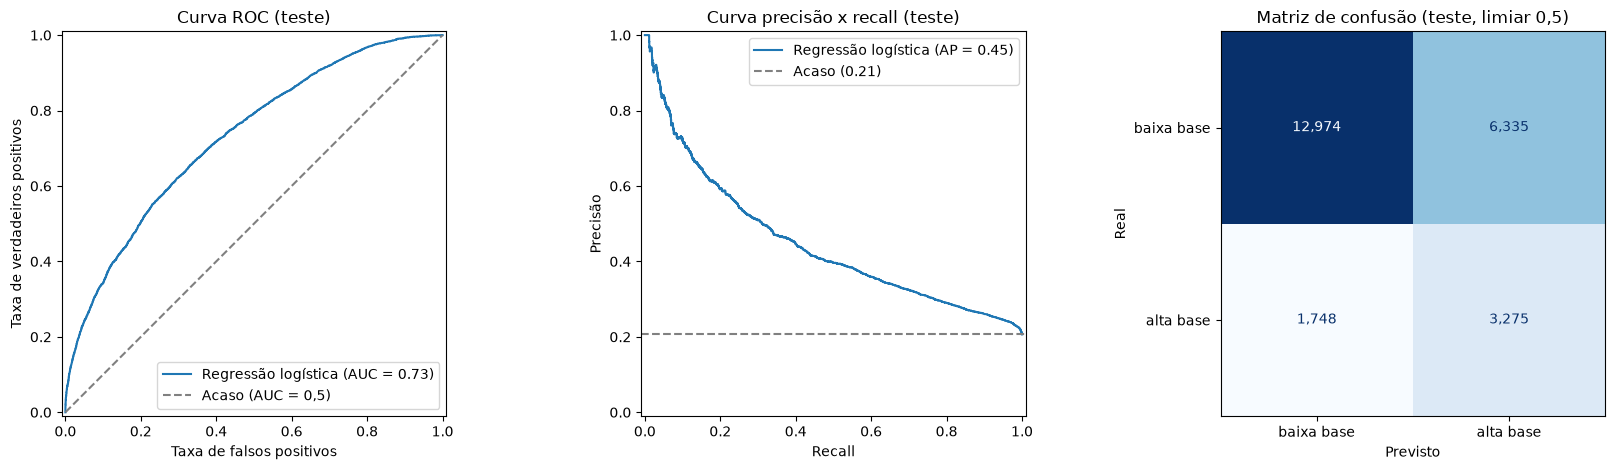

Verdadeiros negativos: 12,974   Falsos positivos: 6,335   Falsos negativos: 1,748   Verdadeiros positivos: 3,275


In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

RocCurveDisplay.from_predictions(y_teste, prob_teste, name="Regressão logística", ax=axes[0])
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Acaso (AUC = 0,5)")
axes[0].set(title="Curva ROC (teste)", xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos")
axes[0].legend(loc="lower right")

PrecisionRecallDisplay.from_predictions(y_teste, prob_teste, name="Regressão logística", ax=axes[1])
axes[1].axhline(y_teste.mean(), linestyle="--", color="gray", label=f"Acaso ({y_teste.mean():.2f})")
axes[1].set(title="Curva precisão x recall (teste)", xlabel="Recall", ylabel="Precisão")
axes[1].legend(loc="upper right")

ConfusionMatrixDisplay(
    confusion_matrix(y_teste, pred_teste), display_labels=["baixa base", "alta base"]
).plot(ax=axes[2], cmap="Blues", colorbar=False, values_format=",d")
axes[2].set(title="Matriz de confusão (teste, limiar 0,5)", xlabel="Previsto", ylabel="Real")
axes[2].grid(False)

plt.tight_layout()
fig.savefig(FIGURAS / "previsao_owners_avaliacao.png", dpi=150, bbox_inches="tight")
plt.show()

vn, fp, fn, vp = confusion_matrix(y_teste, pred_teste).ravel()
print(f"Verdadeiros negativos: {vn:,}   Falsos positivos: {fp:,}   Falsos negativos: {fn:,}   Verdadeiros positivos: {vp:,}")

**Resultado:**

- **AUC-ROC no teste = 0,729, IC 95% [0,721; 0,737].** O intervalo fica inteiro acima de 0,5 e nenhuma das 2.000 reamostragens ficou abaixo desse valor: **rejeitamos H₀**. O modelo distingue jogos de alta e baixa base melhor que o acaso.
- A validação cruzada no treino dá 0,725 ± 0,005, praticamente o mesmo valor do teste: não há sinal de sobreajuste.
- **AUC-PR = 0,448**, contra 0,206 de um classificador ao acaso (2,2 vezes melhor).
- **No limiar 0,5:** recall de 65,2% (o modelo encontra 3.275 dos 5.023 jogos de alta base do teste) e precisão de 34,1% (de cada 3 jogos que ele aponta como alta base, 2 não são).
- A acurácia (66,8%) fica abaixo da de prever sempre "baixa base" (79,4%). Isso é esperado: esse classificador ingênuo acerta 79% sem encontrar nenhum jogo de alta base (recall 0). A comparação justa é a acurácia balanceada: 0,662 contra 0,500.

**Leitura:** uma AUC de 0,73 significa que, sorteando um jogo de alta base e um de baixa base, o modelo dá nota maior ao de alta base em 73% das vezes. É uma capacidade de separação **moderada**.

### 2.5 Quais atributos ajudam a prever?

Primeiro, quanto cada grupo de atributos contribui (AUC-ROC em validação cruzada no treino). Depois, os coeficientes do modelo completo em forma de **razão de chances** (*odds ratio*): acima de 1 aumenta a chance de alta base, abaixo de 1 diminui.

In [ ]:
combinacoes = {
    "só preço": ["preço"],
    "só gênero": ["gênero"],
    "só categorias": ["categorias"],
    "só desenvolvedor": ["desenvolvedor"],
    "preço + gênero": ["preço", "gênero"],
    "preço + gênero + categorias": ["preço", "gênero", "categorias"],
    "todos (modelo final)": ATRIBUTOS,
}
linhas = {}
for rotulo, grupos_modelo in combinacoes.items():
    auc = cross_val_score(montar_modelo(grupos_modelo), X_treino, y_treino, cv=cv, scoring="roc_auc")
    linhas[rotulo] = {"AUC-ROC (CV)": auc.mean(), "desvio": auc.std()}
ablacao = pd.DataFrame(linhas).T
print(ablacao.round(4).to_string())

                             AUC-ROC (CV)  desvio
só preço                           0.6189  0.0052
só gênero                          0.6238  0.0013
só categorias                      0.6864  0.0053
só desenvolvedor                   0.5790  0.0034
preço + gênero                     0.6527  0.0025
preço + gênero + categorias        0.7211  0.0053
todos (modelo final)               0.7254  0.0050


Atributos numéricos:
                                            atributo  coeficiente  razão de chances
Nº de jogos do desenvolvedor (log, +1 desvio-padrão)        0.206             1.229
                       Preço (log, +1 desvio-padrão)        0.236             1.267
                                       Jogo gratuito        1.365             3.915


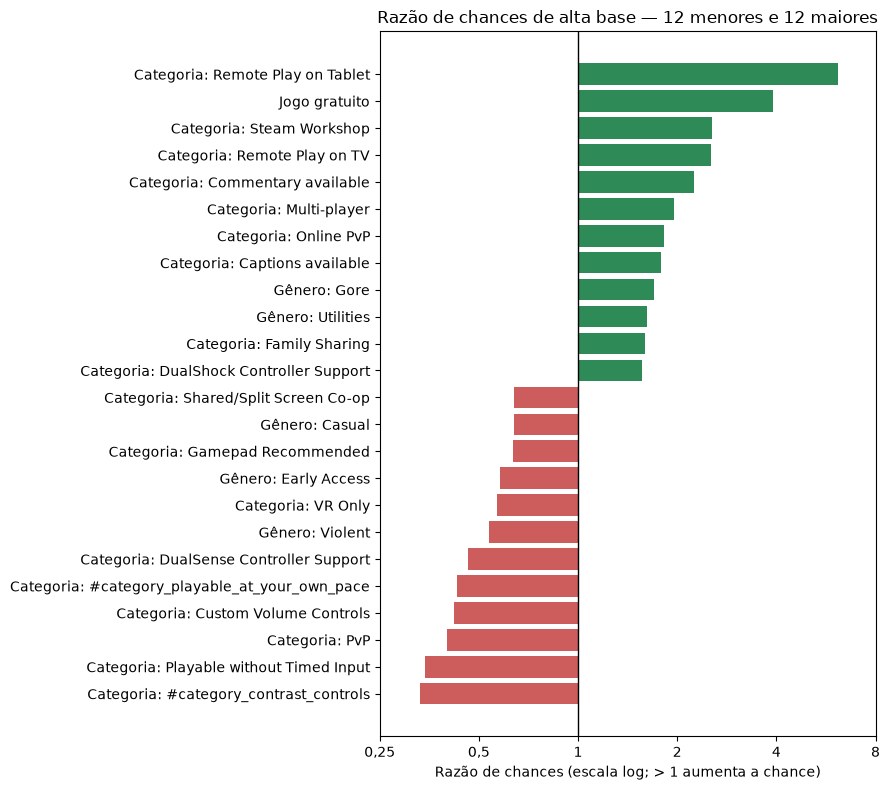

                                      atributo  coeficiente  razão de chances
        Categoria: #category_contrast_controls       -1.106             0.331
       Categoria: Playable without Timed Input       -1.069             0.343
                                Categoria: PvP       -0.919             0.399
             Categoria: Custom Volume Controls       -0.870             0.419
Categoria: #category_playable_at_your_own_pace       -0.844             0.430
       Categoria: DualSense Controller Support       -0.773             0.462
                               Gênero: Violent       -0.625             0.535
                            Categoria: VR Only       -0.563             0.569
                          Gênero: Early Access       -0.546             0.579
                Categoria: Gamepad Recommended       -0.455             0.634
                                Gênero: Casual       -0.450             0.638
          Categoria: Shared/Split Screen Co-op       -0.447     

In [ ]:
nomes = modelo["pre"].get_feature_names_out()
rotulos = {
    "preco_log__log_price": "Preço (log, +1 desvio-padrão)",
    "preco_gratuito__gratuito_num": "Jogo gratuito",
    "dev__log_jogos_do_dev": "Nº de jogos do desenvolvedor (log, +1 desvio-padrão)",
}
coef = pd.DataFrame({
    "atributo": [rotulos.get(n, n.replace("genero__", "Gênero: ").replace("categoria__", "Categoria: ")) for n in nomes],
    "coeficiente": modelo["logistica"].coef_[0],
})
coef["razão de chances"] = np.exp(coef["coeficiente"])
coef = coef.sort_values("coeficiente")

print("Atributos numéricos:")
print(coef[coef["atributo"].isin(rotulos.values())].round(3).to_string(index=False))

extremos = pd.concat([coef.head(12), coef.tail(12)])
fig, ax = plt.subplots(figsize=(9, 8))
cores = ["indianred" if c < 0 else "seagreen" for c in extremos["coeficiente"]]
ax.barh(extremos["atributo"], extremos["razão de chances"] - 1, left=1, color=cores)
ax.axvline(1, color="black", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8], labels=["0,25", "0,5", "1", "2", "4", "8"])
ax.minorticks_off()
ax.set(title="Razão de chances de alta base — 12 menores e 12 maiores",
       xlabel="Razão de chances (escala log; > 1 aumenta a chance)")
plt.tight_layout()
fig.savefig(FIGURAS / "previsao_owners_coeficientes.png", dpi=150, bbox_inches="tight")
plt.show()

print(extremos.round(3).to_string(index=False))

As categorias com coeficientes mais extremos podem estar medindo outra coisa. Conferimos o ano mediano de lançamento dos jogos que têm cada uma:

In [ ]:
extremas = [
    "#category_contrast_controls", "Playable without Timed Input", "Custom Volume Controls",
    "#category_playable_at_your_own_pace", "DualSense Controller Support",
    "Remote Play on Tablet", "Remote Play on TV", "Commentary available", "Captions available", "Steam Workshop",
]
por_categoria = base[["ano", "alta_base", "categories"]].explode("categories")
resumo_cat = por_categoria[por_categoria["categories"].isin(extremas)].groupby("categories").agg(
    jogos=("alta_base", "size"),
    ano_mediano=("ano", "median"),
    pct_alta_base=("alta_base", lambda s: round(s.mean() * 100, 1)),
).loc[extremas]
print(f"Ano mediano de lançamento na base de modelagem: {base['ano'].median():.0f}\n")
print(resumo_cat.to_string())

Ano mediano de lançamento na base de modelagem: 2023

                                     jogos  ano_mediano  pct_alta_base
categories                                                            
#category_contrast_controls            288       2026.0            2.8
Playable without Timed Input         14092       2026.0            6.6
Custom Volume Controls               13587       2026.0            8.0
#category_playable_at_your_own_pace   2267       2026.0            2.2
DualSense Controller Support          4016       2026.0           18.0
Remote Play on Tablet                 1037       2019.0           71.0
Remote Play on TV                     2611       2019.0           55.2
Commentary available                   281       2018.0           47.7
Captions available                    1587       2019.0           42.3
Steam Workshop                        2937       2022.0           46.4


**Contribuição de cada grupo:**

- **Categorias** são o grupo mais informativo sozinho (AUC 0,686), seguidas de gênero (0,624) e preço (0,619).
- **Desenvolvedor**, na forma usada (nº de jogos), é o mais fraco (0,579) e quase não acrescenta ao modelo: 0,721 sem ele, 0,725 com ele.
- Os grupos se complementam: juntos chegam a 0,725.

**Coeficientes:**

- **Jogo gratuito** multiplica a chance de alta base por ~3,9 em relação a um jogo pago de preço muito baixo. Entre os pagos, cada desvio-padrão a mais no log do preço multiplica a chance por ~1,27.
- Categorias ligadas a **multijogador e comunidade** aumentam a chance: Steam Workshop (2,6), Multi-player (2,0), Online PvP (1,8).
- **Casual** (0,64), **Early Access** (0,58) e **VR Only** (0,57) diminuem.

**Cuidado na interpretação:**

- **Várias categorias são, na prática, um relógio.** As de acessibilidade com coeficiente mais negativo (*Custom Volume Controls*, *Playable without Timed Input*, controles de contraste) têm ano mediano de lançamento 2026: a Steam as criou há pouco tempo e só jogos novos as têm. As de coeficiente mais positivo (*Remote Play on Tablet/TV*, *Captions available*) têm ano mediano 2018–2019. O modelo está usando essas categorias para adivinhar a idade do jogo, e jogos mais antigos tiveram mais tempo para acumular donos.
- Os coeficientes são associações, não causas. Marcar "Steam Workshop" na página não traz jogadores.
- Categorias correlacionadas dividem o efeito entre si (PvP tem razão 0,40 e Online PvP 1,82), então cada coeficiente isolado deve ser lido com cautela.

### 2.6 Checagens de robustez

Três perguntas que podem mudar a leitura do resultado:

1. **Idade do jogo.** Jogos antigos tiveram mais tempo para acumular donos. O ano de lançamento é conhecido no lançamento, mas não está na lista de atributos da pergunta. Quanto o modelo ganha se ele entrar?
2. **Steam Trading Cards.** Quanto a AUC subiria se a categoria suspeita de vazamento ficasse no modelo?
3. **Duplicatas (Parte 1).** O resultado muda se usarmos a base completa?

In [ ]:
def auc_teste_de(pipeline, Xa, ya, Xb, yb):
    return roc_auc_score(yb, pipeline.fit(Xa, ya).predict_proba(Xb)[:, 1])


robustez = {"modelo final (preço, gênero, categorias, desenvolvedor)": auc_teste}

# 1. Ano de lançamento
robustez["+ ano de lançamento"] = auc_teste_de(montar_modelo(ATRIBUTOS + ["ano"]), X_treino, y_treino, X_teste, y_teste)
robustez["só ano de lançamento"] = auc_teste_de(montar_modelo(["ano"]), X_treino, y_treino, X_teste, y_teste)

# 2. Com Steam Trading Cards
com_cartas = montar_modelo(ATRIBUTOS, categorias=lista_completa)
robustez["+ categoria Steam Trading Cards"] = auc_teste_de(com_cartas, X_treino, y_treino, X_teste, y_teste)

# 3. Base completa (com duplicatas)
completa_m = jogos.dropna(subset=["owners_mid", "price"]).copy()
completa_m["alta_base"] = (completa_m["owners_mid"] > ALVO_CORTE).astype(int)
completa_m["gratuito_num"] = (completa_m["price"] == 0).astype(int)
completa_m["ano_num"] = completa_m["ano"].astype("float")
Xa, Xb, ya, yb = train_test_split(
    completa_m[colunas_x], completa_m["alta_base"], test_size=0.2,
    stratify=completa_m["alta_base"], random_state=SEMENTE,
)
robustez["base completa (com duplicatas)"] = auc_teste_de(montar_modelo(ATRIBUTOS), Xa, ya, Xb, yb)

print(pd.Series(robustez, name="AUC-ROC (teste)").round(4).to_string())

# Duplicatas divididas entre treino e teste na base completa
duplicados = completa_m.index[jogos.loc[completa_m.index, "dup_grupo"] > 1]
chaves = chave.loc[duplicados].apply(tuple, axis=1)
chaves_treino = set(chaves[chaves.index.isin(Xa.index)])
vazadas = int(chaves[chaves.index.isin(Xb.index)].isin(chaves_treino).sum())
print(f"\nBase completa: {vazadas} jogos do teste têm uma cópia do mesmo jogo no treino.")

modelo final (preço, gênero, categorias, desenvolvedor)    0.7290
+ ano de lançamento                                        0.8183
só ano de lançamento                                       0.7715
+ categoria Steam Trading Cards                            0.7756
base completa (com duplicatas)                             0.7297

Base completa: 31 jogos do teste têm uma cópia do mesmo jogo no treino.


**Resultado:**

1. **A idade do jogo pesa mais que todos os atributos da pergunta juntos.** Só o ano de lançamento dá AUC 0,772, acima dos 0,729 do modelo final. Com o ano no modelo, a AUC sobe para 0,818. O motivo é o alvo: `estimated_owners` é o **acumulado até hoje**, não o desempenho no lançamento.
2. **Steam Trading Cards carrega muito sinal** (0,729 → 0,776), o que reforça a suspeita de vazamento. Mantê-la fora deixa o resultado mais honesto.
3. **As duplicatas não mudam o modelo** (0,7297 com elas, 0,7290 sem). Na base completa, 31 jogos do teste têm uma cópia no treino, número pequeno demais para inflar a métrica. Coerente com a Parte 1.

## Conclusão

**Parte 1 — Duplicatas.** A limpeza não remove duplicatas. A base tem 105 linhas a mais de 67 jogos cadastrados mais de uma vez (0,07%); os demais nomes repetidos são homônimos. Removê-las não altera nenhuma conclusão da Entrega 2.

**Parte 2 — Previsão de base de jogadores.**

**Resposta à pergunta: sim, mas só em parte.** Com preço, gênero, categorias e desenvolvedor, a regressão logística separa jogos de alta e baixa base melhor que o acaso (AUC-ROC 0,729, IC 95% [0,721; 0,737]; rejeitamos H₀). A capacidade é moderada: no limiar padrão o modelo encontra 65% dos jogos de alta base, mas acerta só 34% das vezes em que aponta um. Serve para ordenar jogos por chance de sucesso, não para decidir o destino de um jogo específico.

- O que mais ajuda: categorias, depois gênero e preço (principalmente ser gratuito). O desenvolvedor, medido pelo nº de jogos, ajuda pouco.
- O que a página não mostra (qualidade, marketing, marca) explica a maior parte do resultado.

**Limitações:**

- **O alvo é acumulado.** Jogos antigos tiveram mais tempo para juntar donos, e o ano de lançamento sozinho prevê melhor (AUC 0,772) que os atributos da pergunta. Parte do sinal das categorias é idade disfarçada.
- **A página é a de hoje, não a do lançamento.** Preço, gêneros e categorias são os atuais; jogos mudam de preço e ganham recursos depois de lançados.
- **`estimated_owners` é uma estimativa em faixas** do SteamSpy. O corte em 20 mil é o único que a base permite sem uma classe positiva minúscula.
- **Desenvolvedor foi reduzido a uma contagem**, que inclui jogos lançados depois. O histórico de sucesso do estúdio não entrou.
- **A regressão logística é linear:** não captura interações (por exemplo, gratuito + multijogador).
- 22.476 jogos sem faixa de proprietários ou sem preço ficaram fora.
